# XGBoost Multi-Horizon Baseline — JalVaani

Direct h-step forecasting: **one separate XGBoost model per horizon** (t+7, t+14, t+30).

Target for horizon h = `gwl_mean` shifted −h days **per district** to prevent cross-district leakage.

**SHAP analysis** is run for each horizon — the evolution of feature importance across horizons
directly justifies why TFT's multi-scale attention is needed.

> Outputs: prediction CSVs, SHAP CSVs, SHAP bar plots — all in `outputs/`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from pathlib import Path
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size']  = 11

MASTER   = Path('../../../data/clean/master_dataset.csv')
OUT_DIR  = Path('../../../04_results/phase1_baselines')
PLOT_DIR = OUT_DIR / 'plots'
OUT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

TRAIN_END = '2024-09-30'
VAL_END   = '2025-01-31'
HORIZONS  = [7, 14, 30]
COLORS    = {7: '#e41a1c', 14: '#ff7f00', 30: '#377eb8'}

FEATURE_COLS = [
    'gwl_lag_7', 'gwl_lag_14', 'gwl_lag_30',
    'gwl_7d_change', 'gwl_30d_change',
    'rainfall_mm', 'rainfall_7d', 'rainfall_30d',
    'et_mm', 'soil_moisture', 'net_water_balance',
    'temp_max', 'temp_min', 'temp_mean', 'humidity_mean', 'vpd_approx',
    'month', 'day_of_year', 'is_monsoon',
    'district_id',
    'sand_0cm', 'clay_0cm', 'silt_0cm',
    'sand_10cm', 'clay_10cm', 'silt_10cm',
    'sand_30cm', 'clay_30cm', 'silt_30cm',
]

XGB_PARAMS = dict(
    n_estimators=600, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42, n_jobs=-1,
    early_stopping_rounds=30, eval_metric='rmse', verbosity=0,
)

def compute_metrics(actual, pred):
    a, p = np.array(actual, float), np.array(pred, float)
    rmse = np.sqrt(np.mean((a-p)**2))
    mae  = np.mean(np.abs(a-p))
    mask = a != 0
    mape = np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100 if mask.any() else np.nan
    return rmse, mae, mape

print('Config loaded ✓')
print(f'  Horizons: {HORIZONS}')
print(f'  Features: {len(FEATURE_COLS)}')

Config loaded ✓
  Horizons: [7, 14, 30]
  Features: 29


## 1. Load & Prepare Data

In [2]:
df = pd.read_csv(MASTER, parse_dates=['date'])
df = df.sort_values(['district', 'date']).reset_index(drop=True)
print(f'Loaded: {len(df):,} rows | {df["district"].nunique()} districts')

# Shift targets per district (avoid cross-district contamination)
for h in HORIZONS:
    df[f'target_t{h}'] = df.groupby('district')['gwl_mean'].shift(-h)

df['split'] = 'train'
df.loc[df['date'] > TRAIN_END, 'split'] = 'val'
df.loc[df['date'] > VAL_END,   'split'] = 'test'

available_feats = [c for c in FEATURE_COLS if c in df.columns]
df_clean = df.dropna(subset=available_feats)
print(f'Features available: {len(available_feats)}')
print(f'Rows after feature NaN drop: {len(df_clean):,}')
print(f'Split counts: {df_clean["split"].value_counts().to_dict()}')

Loaded: 16,785 rows | 24 districts
Features available: 29
Rows after feature NaN drop: 13,437
Split counts: {'train': 9462, 'val': 2405, 'test': 1570}


## 2. Train XGBoost — One Model Per Horizon

In [3]:
models   = {}
summary  = []

for h in HORIZONS:
    print(f'\n{"="*55}')
    print(f'  Horizon t+{h}')
    print(f'{"="*55}')

    df_h  = df_clean.dropna(subset=[f'target_t{h}']).copy()
    train = df_h[df_h['split'] == 'train']
    val   = df_h[df_h['split'] == 'val']
    test  = df_h[df_h['split'] == 'test']

    X_tr, y_tr = train[available_feats], train[f'target_t{h}']
    X_va, y_va = val[available_feats],   val[f'target_t{h}']
    X_te, y_te = test[available_feats],  test[f'target_t{h}']
    print(f'  Train: {len(X_tr):,}  Val: {len(X_va):,}  Test: {len(X_te):,}')

    m = xgb.XGBRegressor(**XGB_PARAMS)
    m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=50)
    models[h] = m

    print(f'  Best iteration: {m.best_iteration}')

    val_pred  = m.predict(X_va)
    test_pred = m.predict(X_te)

    vr, vm, vp = compute_metrics(y_va.values, val_pred)
    tr, tm, tp = compute_metrics(y_te.values, test_pred)
    print(f'  Val  RMSE={vr:.4f}m  MAE={vm:.4f}m  MAPE={vp:.2f}%')
    print(f'  Test RMSE={tr:.4f}m  MAE={tm:.4f}m  MAPE={tp:.2f}%')

    summary.append({'Horizon': f't+{h}', 'Val RMSE': round(vr,4), 'Val MAE': round(vm,4),
                    'Test RMSE': round(tr,4), 'Test MAE': round(tm,4), 'Test MAPE': round(tp,2)})

    # Save predictions
    val_cp          = val.copy()
    val_cp['gwl_pred']   = val_pred
    val_cp['gwl_actual'] = y_va.values
    val_cp['split']      = 'val'
    test_cp         = test.copy()
    test_cp['gwl_pred']  = test_pred
    test_cp['gwl_actual']= y_te.values
    test_cp['split']     = 'test'

    pred_df = pd.concat([
        val_cp[['district','date','gwl_actual','gwl_pred','split']],
        test_cp[['district','date','gwl_actual','gwl_pred','split']],
    ], ignore_index=True)
    pred_df['horizon'] = h
    pred_df.to_csv(OUT_DIR / f'xgboost_multihorizon_t{h}.csv', index=False)
    print(f'  Saved → xgboost_multihorizon_t{h}.csv')

print('\n✅ All horizons trained')


  Horizon t+7
  Train: 9,462  Val: 2,405  Test: 1,430
[0]	validation_0-rmse:9.83631
[50]	validation_0-rmse:2.30841
[100]	validation_0-rmse:2.14330
[122]	validation_0-rmse:2.13023
  Best iteration: 92
  Val  RMSE=2.1294m  MAE=0.8295m  MAPE=21.16%
  Test RMSE=3.9210m  MAE=1.5551m  MAPE=9.44%
  Saved → xgboost_multihorizon_t7.csv

  Horizon t+14
  Train: 9,462  Val: 2,405  Test: 1,290
[0]	validation_0-rmse:9.86925
[50]	validation_0-rmse:2.79262
[100]	validation_0-rmse:2.66224
[150]	validation_0-rmse:2.65160
[186]	validation_0-rmse:2.65393
  Best iteration: 157
  Val  RMSE=2.6468m  MAE=1.1612m  MAPE=26.77%
  Test RMSE=4.5080m  MAE=1.8697m  MAPE=12.31%
  Saved → xgboost_multihorizon_t14.csv

  Horizon t+30
  Train: 9,462  Val: 2,405  Test: 970
[0]	validation_0-rmse:10.12569
[50]	validation_0-rmse:3.49697
[100]	validation_0-rmse:3.28902
[150]	validation_0-rmse:3.25211
[199]	validation_0-rmse:3.25622
  Best iteration: 169
  Val  RMSE=3.2519m  MAE=1.5625m  MAPE=30.76%
  Test RMSE=5.2570m  MAE

## 3. Training Curve Comparison

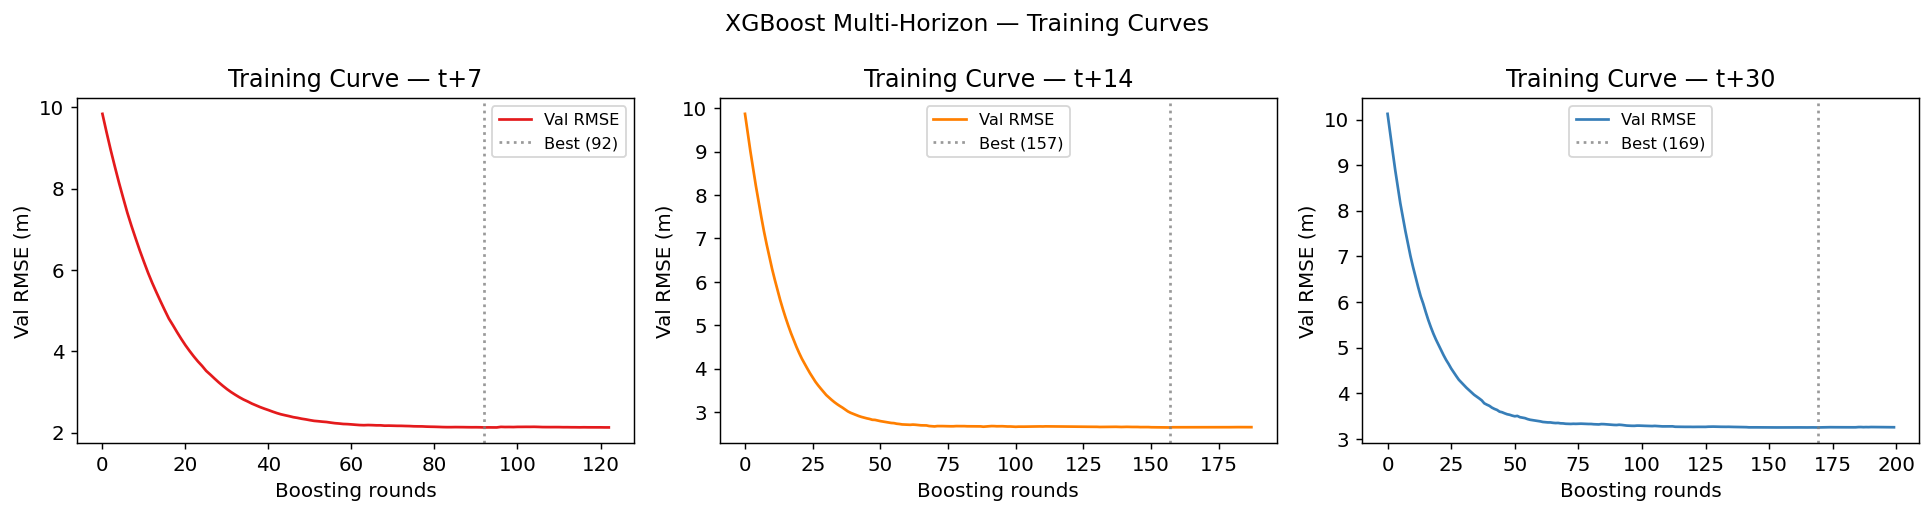

In [4]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5*len(HORIZONS), 4), sharey=False)
for ax, h in zip(axes, HORIZONS):
    hist = models[h].evals_result()
    train_rmse = hist['validation_0']['rmse'] if 'validation_0' in hist else []
    if not train_rmse:
        ax.set_title(f't+{h} (no history)')
        continue
    ax.plot(train_rmse, color=COLORS[h], label='Val RMSE')
    ax.axvline(models[h].best_iteration, color='gray', linestyle=':', alpha=0.8,
               label=f'Best ({models[h].best_iteration})')
    ax.set_title(f'Training Curve — t+{h}')
    ax.set_xlabel('Boosting rounds')
    ax.set_ylabel('Val RMSE (m)')
    ax.legend(fontsize=9)

plt.suptitle('XGBoost Multi-Horizon — Training Curves', fontsize=13)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'xgboost_multihorizon_curves.png', dpi=150)
plt.show()

## 4. SHAP Feature Importance — All Horizons

  SHAP for t+7 ...
    Top-5: ['gwl_lag_7', 'gwl_lag_14', 'gwl_7d_change', 'gwl_lag_30', 'gwl_30d_change']
  SHAP for t+14 ...
    Top-5: ['gwl_lag_7', 'gwl_lag_14', 'gwl_7d_change', 'gwl_lag_30', 'gwl_30d_change']
  SHAP for t+30 ...
    Top-5: ['gwl_lag_7', 'gwl_lag_14', 'gwl_lag_30', 'day_of_year', 'is_monsoon']


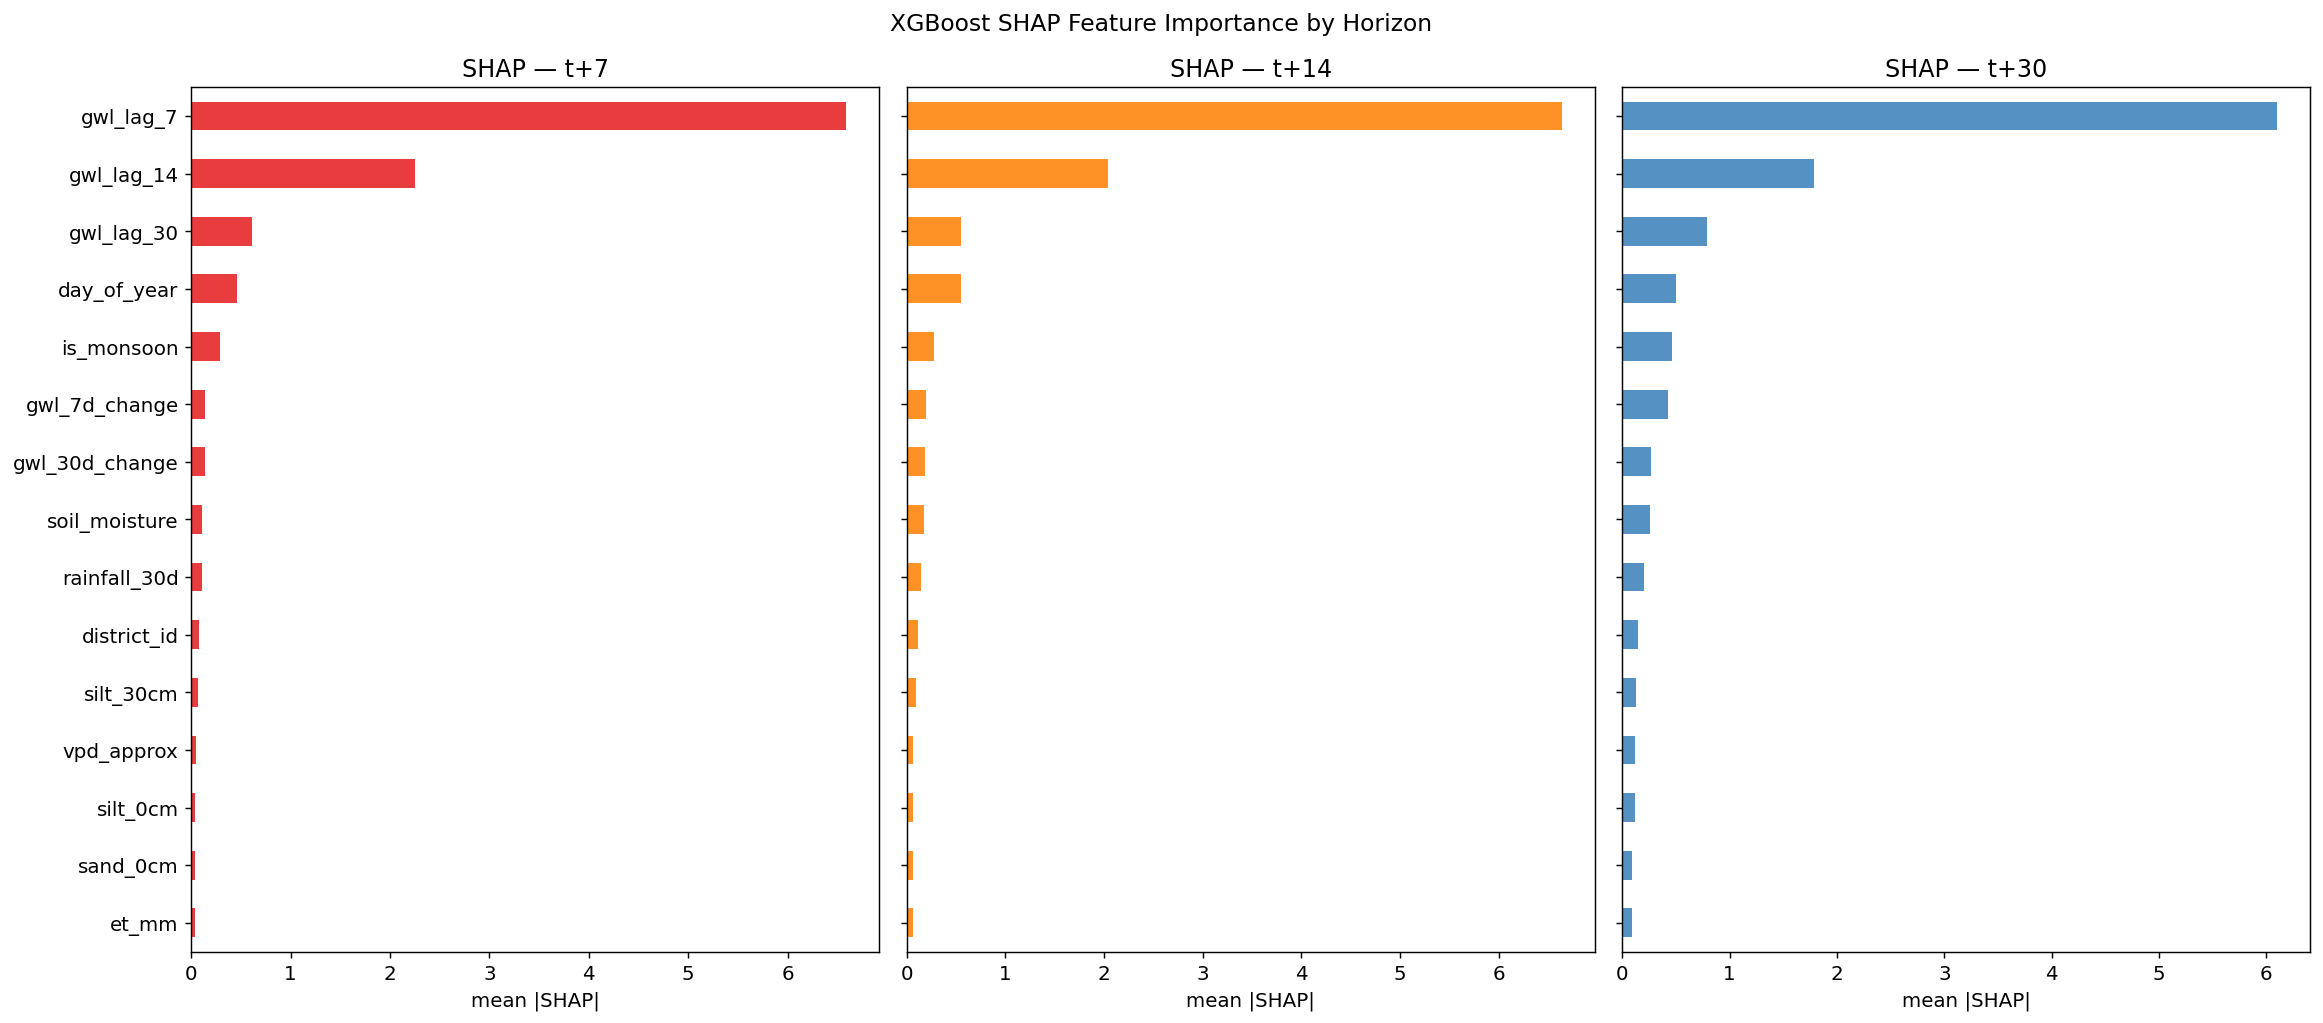


SHAP plots saved ✓


In [5]:
try:
    import shap
    shap_dict = {}

    for h in HORIZONS:
        print(f'  SHAP for t+{h} ...')
        df_h   = df_clean.dropna(subset=[f'target_t{h}'])
        X_te   = df_h[df_h['split'] == 'test'][available_feats]
        rng    = np.random.default_rng(42)
        idx    = rng.choice(len(X_te), size=min(2000, len(X_te)), replace=False)
        X_shap = X_te.iloc[idx]

        explainer   = shap.TreeExplainer(models[h])
        shap_values = explainer.shap_values(X_shap)

        mean_abs = pd.Series(
            np.abs(shap_values).mean(axis=0), index=available_feats
        ).sort_values(ascending=False)
        shap_dict[h] = mean_abs

        shap_df = mean_abs.reset_index()
        shap_df.columns = ['feature', 'mean_abs_shap']
        shap_df.to_csv(OUT_DIR / f'xgboost_shap_t{h}.csv', index=False)
        print(f'    Top-5: {mean_abs.head(5).index.tolist()}')

    # Side-by-side SHAP bar charts
    fig, axes = plt.subplots(1, len(HORIZONS), figsize=(6*len(HORIZONS), 8), sharey=True)
    for ax, h in zip(axes, HORIZONS):
        top = shap_dict[h].head(15).sort_values(ascending=True)
        top.plot(kind='barh', ax=ax, color=COLORS[h], alpha=0.85)
        ax.set_title(f'SHAP — t+{h}')
        ax.set_xlabel('mean |SHAP|')
    plt.suptitle('XGBoost SHAP Feature Importance by Horizon', fontsize=13)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / 'xgboost_shap_multihorizon.png', dpi=150)
    plt.show()

    print('\nSHAP plots saved ✓')

except ImportError:
    print('[SHAP not installed — skip]  pip install shap')
    shap_dict = {}

t+7 : lag=94.0%  env=6.0%  (as horizon grows, env features should rise)
t+14: lag=93.5%  env=6.5%  (as horizon grows, env features should rise)
t+30: lag=91.4%  env=8.6%  (as horizon grows, env features should rise)


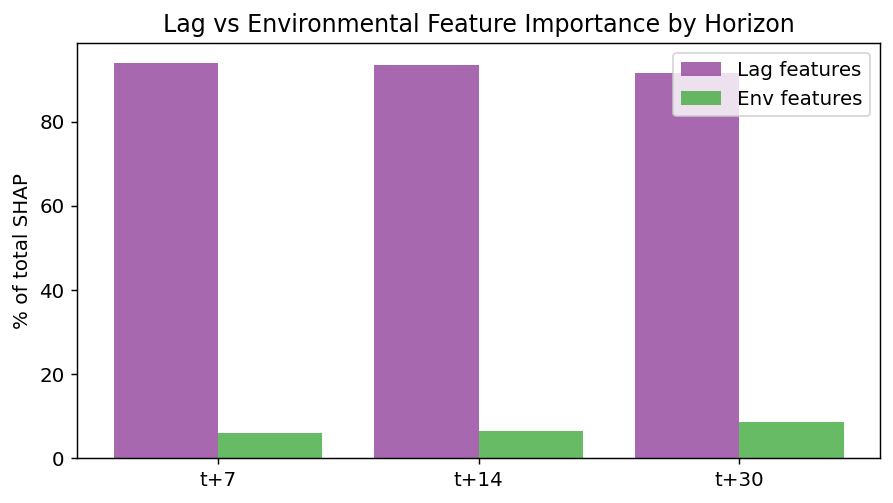

In [6]:
# SHAP lag vs environmental ratio across horizons
if shap_dict:
    LAG_FEATS = ['gwl_lag_7','gwl_lag_14','gwl_lag_30','gwl_7d_change','gwl_30d_change']
    ENV_FEATS = ['rainfall_mm','rainfall_7d','rainfall_30d','et_mm','soil_moisture',
                 'net_water_balance','temp_mean','humidity_mean','vpd_approx']

    ratio_rows = []
    for h, shap in sorted(shap_dict.items()):
        lag  = sum(shap.get(f, 0) for f in LAG_FEATS)
        env  = sum(shap.get(f, 0) for f in ENV_FEATS)
        total = lag + env
        ratio_rows.append({'Horizon': f't+{h}', 'Lag (%)': lag/total*100, 'Env (%)': env/total*100})
        print(f't+{h:<2d}: lag={lag/total*100:.1f}%  env={env/total*100:.1f}%  '
              f'(as horizon grows, env features should rise)')

    ratio_df = pd.DataFrame(ratio_rows)

    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(HORIZONS))
    ax.bar(x - 0.2, ratio_df['Lag (%)'],  0.4, label='Lag features',  color='#984ea3', alpha=0.85)
    ax.bar(x + 0.2, ratio_df['Env (%)'],  0.4, label='Env features',  color='#4daf4a', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([f't+{h}' for h in HORIZONS])
    ax.set_ylabel('% of total SHAP')
    ax.set_title('Lag vs Environmental Feature Importance by Horizon')
    ax.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / 'xgboost_shap_lag_vs_env.png', dpi=150)
    plt.show()

## 5. Summary Table

In [7]:
summary_df = pd.DataFrame(summary)
summary_df.to_csv(OUT_DIR / 'xgboost_multihorizon_summary.csv', index=False)

print('=== XGBoost Multi-Horizon Final Summary ===')
display(
    summary_df.style
    .background_gradient(subset=['Test RMSE','Test MAE','Test MAPE'], cmap='YlOrRd')
    .format({'Val RMSE':'{:.4f}','Val MAE':'{:.4f}',
             'Test RMSE':'{:.4f}','Test MAE':'{:.4f}','Test MAPE':'{:.2f}'})
)

=== XGBoost Multi-Horizon Final Summary ===


,Horizon,Val RMSE,Val MAE,Test RMSE,Test MAE,Test MAPE
0,t+7,2.1294,0.8295,3.9210,1.5551,9.44
1,t+14,2.6468,1.1612,4.5080,1.8697,12.31
2,t+30,3.2519,1.5625,5.2570,2.2199,12.17
